# Build Halo

/home/davidliuyh/WorkSpace/FDM/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ma 1e-22
Using soliton core with rc 0.74 kpc and rhoc 6.25e+07 M_sun/kpc^3
M_tot: 8.92e+09 M_sun
Done.
seed 0
Enclosed mass in rfit_max = 10^9.84547732531432
Iteration #1
Solving for eigenmodes...
Sampling grid for eigenvalue problem includes 137088 bins, out to r_max = 160.0 kpc
(returning only eigenmodes with energies below circular orbits at r_fit = 50.0 kpc)
n_max = 46
l = 0; n_max = 46
l = 1; n_max = 46
l = 2; n_max = 45
l = 3; n_max = 45
l = 4; n_max = 44
l = 5; n_max = 44
l = 6; n_max = 43
l = 7; n_max = 42
l = 8; n_max = 42
l = 9; n_max = 41
l = 10; n_max = 41
l = 11; n_max = 40
l = 12; n_max = 39
l = 13; n_max = 39
l = 14; n_max = 38
l = 15; n_max = 37
l = 16; n_max = 37
l = 17; n_max = 36
l = 18; n_max = 35
l = 19; n_max = 35
l = 20; n_max = 34
l = 21; n_max = 33
l = 22; n_max = 32
l = 23; n_max = 32
l = 24; n_max = 31
l = 25; n_max = 30
l = 26; n_max = 29
l = 27; n_max = 29
l = 28; n_max = 28
l = 29; n_max = 27
l = 30; n_max = 26
l = 31; n_max = 26
l = 32; n_max = 25
l = 33;

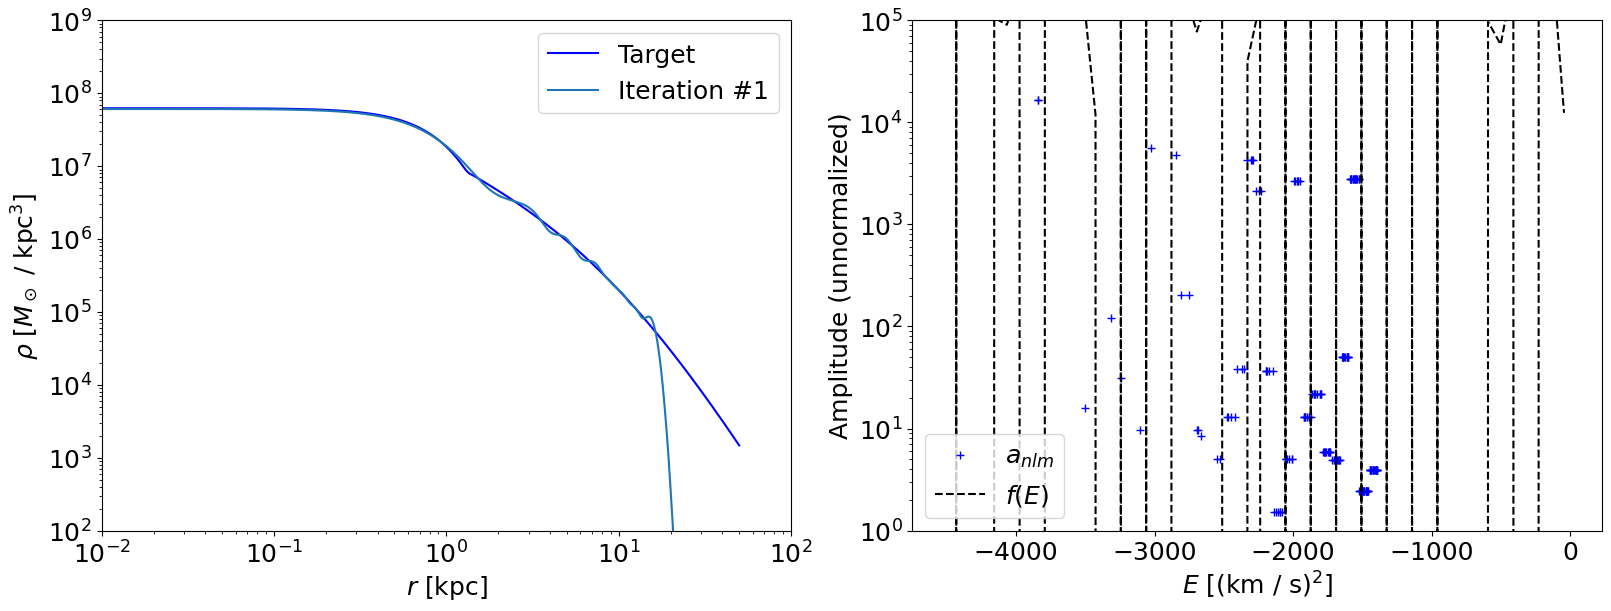

Completed!
Seed 0: total modes=67572, active modes=67572


100%|██████████| 110/110 [2:51:57<00:00, 93.79s/it]  


Done.


Seed 0 potentials: 100%|██████████| 110/110 [00:33<00:00,  3.32it/s]


In [ ]:
import healpy as hp
import fdmtools
import os

# import ctypes
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as scinterp

from tqdm import tqdm
from multiprocessing import Pool, cpu_count
import warnings
# gsl_path="/XYFS01/pxy80/lib"
# os.environ["LD_LIBRARY_PATH"] = gsl_path + ':' + os.environ.get('LD_LIBRARY_PATH','')
# ctypes.cdll.LoadLibrary(gsl_path + '/libintlc.so.5')
# ctypes.cdll.LoadLibrary(gsl_path + '/libirng.so')
# ctypes.cdll.LoadLibrary(gsl_path + '/libsvml.so')
# ctypes.cdll.LoadLibrary(gsl_path + '/libimf.so')
# ctypes.cdll.LoadLibrary(gsl_path + '/libgsl.so.27')
# ctypes.cdll.LoadLibrary(gsl_path + '/libgslcblas.so.0') 

Ggal = 4.30091727e-6
hbar = 6.582119569509067e-16    # Reduced Planck constant in eV * s
c_constant = 2.99792458e5       # Speed of light in km/s

# Conversions:
km_to_kpc = 3.240779289444365e-17       # Conversion from km to kpc
km_s_to_kpc_gyr = 1.022712165045695     # Conversion from km/s to kpc/Gyr

# Cosmology
Om = 0.2865                     # Omega matter
rho_crit = 133.36363195167573   # Critical background density (solMass / kpc^3)
rho_m = rho_crit * Om           # Background matter density at present
overdensity = 347.0             # Overdensity for spherical collapse
rho_vir = overdensity * rho_m   # Average density within the virial radius

# =============================
# Runtime configuration
# =============================
have_soliton = True
m_as = [1.0e-22]                                    # FDM particle mass in eV / c^2
Nmaxes = [None]
seeds = [0]                             # Realizations

# Halo / profile setup
r_setup_res = 256
a = 10.
M = 1e10
R_max = 160.
R_fit = 50.

# Time setup
t_step = 0.1                                         # Gyr
t_stop = 11.
ramp_up = 10
t_array = np.arange(start=0., stop=t_stop, step=t_step)
timesteps = len(t_array)

# Orbit IC setup (used in cell 2)
nparticle = 600000
t_to_Myr = 977.79222168
warnings.filterwarnings('ignore')


for Nmax in Nmaxes:
    for m_a in m_as:
        fdm = fdmtools.FDMTools(m_a)                          # Initialize FDM tools
    
        print(f'ma {m_a}')
        h_over_m = hbar / (m_a / c_constant**2) * km_to_kpc     # Scaled unit (h_bar / m_a) in astrophysical units: (kpc * km / s)
    
        # Define Base Potential
        r_setup = np.logspace(-3, 3, r_setup_res)
    
        rho_arr = M / (2. * np.pi * a**3) / (r_setup / a) / (1. + r_setup / a)**3
    
        alpha = 1./3.
        rc = 1.6 * (m_a / 1e-22)**-1 * (M / 1e9)**(-alpha)
        rhoc = 0.019 * (m_a / 1e-22)**-2 * rc**-4 / (1. + 0.091*(r_setup/rc)**2)**8 * 1e9
        transition = np.max(np.where(rhoc > rho_arr)) + 1
    
        rhoh = np.concatenate((rhoc[:transition], rho_arr[transition:]))
        if have_soliton:
            print(f'Using soliton core with rc {rc:.2f} kpc and rhoc {rhoc[0]:.2e} M_sun/kpc^3')
            rho_in = scinterp.CubicSpline(r_setup, rhoh)
        else:
            print('Using NFW profile without soliton core')
            rho_in = scinterp.CubicSpline(r_setup, rho_arr)
    
        #initialize potential
        phi, rho, M_tot = fdm.initialize_potential(rho_in, core=False, r_max=R_max)
        print(f'M_tot: {M_tot:.2e} M_sun')
    
        #invert the distribution function
        fE = fdm.DF_invert(phi, rho)
    
        print('Done.')
    
        folder = f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}_curve' if have_soliton else f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}_nosoliton_curve'
        if Nmax is not None:
            folder = f'{folder}_Nmax{Nmax}'
    
        
        for seed in seeds:
            print(f'seed {seed}')
    
            # Calculate eigenmodes and assign amplitudes
            E_nl, R_nl, a_nlm, phase_nlm, den, den_list = fdm.solve_amps_itr(
                R_max, R_fit, phi, rho, M, fE,
                maxiter=1, method='Isotropic', bins=50, schwarz_iter=2500, seed=seed
            )
            if Nmax is not None:
                n_idx = np.arange(a_nlm.shape[0])[:, None]
                l_idx = np.arange(a_nlm.shape[1])[None, :]
                n_principle = n_idx + l_idx + 1
                a_nlm[n_principle > Nmax] = 0.

            # Plot density profile after base-mode truncation (same spirit as solve_amps_itr diagnostics)
            r_profile = np.logspace(-2, np.log10(R_fit), 200)
            den_base_profile, _ = fdm.den_from_amps(r_profile, a_nlm, R_nl)
            plt.figure(figsize=(8, 6))
            plt.loglog(r_profile, rho_in(r_profile), 'k--', label='Target')
            plt.loglog(r_profile, den_base_profile, 'b-', label='Halo from truncated a_nlm')
            plt.xlim(0.01, R_fit)
            plt.xlabel(r'$r$ [kpc]')
            plt.ylabel(r'$\rho$ [$M_\odot$ / kpc$^3$]')
            plt.legend()
            plt.title(f'Nmax={Nmax}, seed={seed}')
            
            # Radius grid for reconstruction
            r_array = np.arange(start=0., stop=30., step=0.1)
            r_steps = 251
            r_array[0] = 0.00001
    
            # Export to Agama format
    
            prefix = f'{folder}/s{seed}'
            if not os.path.exists(prefix):
                os.makedirs(prefix)
            nmax_tag = 'all' if Nmax is None else str(Nmax)
            plt.savefig(f'{prefix}/density_profile_n{nmax_tag}.png', dpi=150)
            plt.close()
    
            shape = np.shape(a_nlm)
            nmax_eff = shape[0]
            valid_nl = E_nl != 0.
            l_values = np.arange(shape[1])
            total_modes = int(np.sum(valid_nl * (2 * l_values[None, :] + 1)))
            active_nl = valid_nl & (a_nlm != 0.)
            active_modes = int(np.sum(active_nl * (2 * l_values[None, :] + 1)))
            print(f"Seed {seed}: total modes={total_modes}, active modes={active_modes}")
    
            for ti in tqdm(range(timesteps)):
    
                timestep = t_array[ti]
                NSIDE = 12
                NPIX = hp.nside2npix(NSIDE)
                rho_lms_size = hp.Alm.getsize(3 * NSIDE - 1)
    
                grid = np.zeros((r_steps, NPIX))
                rho_lms = np.zeros((r_steps, rho_lms_size), dtype=complex)
    
                lmax = shape[1] - 1  # 原来代码没有
    
                for i in range(r_steps):
    
                    a_nlm_real = np.zeros((lmax+2)*(lmax+1)//2, dtype=complex)
                    a_nlm_imag = np.zeros((lmax+2)*(lmax+1)//2, dtype=complex)
    
                    for l in range(shape[1]):
                        for m in range(0, l+1):
                            AR = 0.
                            idx = (2*lmax+3-m)*m//2 + (l-m)
                            for n in range(nmax_eff):
                                if E_nl[n, l] == 0.:
                                    continue
                                AR = a_nlm[n, l] * R_nl[n, l](r_array[i])
                                phase_new = -E_nl[n, l] / h_over_m * km_s_to_kpc_gyr * timestep
                                alm = np.cos(phase_nlm[n, l, m] + phase_new) + 1.j * np.sin(phase_nlm[n, l, m] + phase_new)
                                almm = (np.cos(phase_nlm[n, l, -m] + phase_new) - 1.j * np.sin(phase_nlm[n, l, -m] + phase_new)) * (-1.)**m
                                if m == 0:
                                    a_nlm_real[idx] += AR * alm
                                    a_nlm_imag[idx] += AR * alm / (1.j)
                                else:
                                    a_nlm_real[idx] += AR / 2. * (alm + almm)
                                    a_nlm_imag[idx] += AR / 2.j * (alm - almm)
    
                    new_map_real = hp.alm2map(a_nlm_real, nside=NSIDE)
                    new_map_imag = hp.alm2map(a_nlm_imag, nside=NSIDE) * 1.j
                    new_map = new_map_real + new_map_imag
    
                    if ti < ramp_up:
                        rat = ti / ramp_up
                    else:
                        rat = 1.
    
                    grid[i] = rat * np.abs(new_map)**2
                    rho_lms[i] = hp.map2alm(grid[i])
    
                lmax = hp.Alm.getlmax(rho_lms.shape[1])
    
                f = open(f"{prefix}/sph_harm_gradual"+str(ti).zfill(3)+".ini", "w")
                f.write('[Density]\n')
                f.write('type=DensitySphericalHarmonic\n')
                f.write('gridSizeR='+str(r_steps)+'\n')
                f.write('lmax='+str(lmax)+'\n')
                f.write('Coefficients\n')
                f.write('#rho\n')
                f.write(f'{"#radius": <17}')
                for l in range(lmax+1):
                    for m in range(-l,l+1):
                        f.write(f'{"l="+str(l)+",m="+str(m): <17}')
                f.write('\n')
    
                for i in range(r_steps):
                    f.write(f"{r_array[i]:{16}.{10}}")
                    for l in range(lmax+1):
                        for m in range(-l,l+1):
                            if m>0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = np.sqrt(2) * rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m==0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m<0:
                                idx = (2*lmax+3+m)*(-m)//2 + (l+m)
                                alm_p = rho_lms[i,idx]
                                alm_m = rho_lms[i,idx].conjugate()
                                rho_lm = -np.sqrt(2) * rho_lms[i,idx].imag / (np.sqrt(4. * np.pi))
                            f.write(' '+f"{rho_lm:{16}.{10}}")
                    f.write('\n')
    
                f.close()
    
            dens = np.zeros(r_steps)
            shape = np.shape(a_nlm)
            for l in range(shape[1]):
                for n in range(nmax_eff):
                    if E_nl[n, l] == 0.:
                        continue
                    dens += a_nlm[n, l]**2 * R_nl[n, l](r_array[0:r_steps])**2 * (2 * l + 1) / np.pi / 4.
    
            NSIDE = 3
            NPIX = hp.nside2npix(NSIDE)
            rho_lms_size = hp.Alm.getsize(3 * NSIDE - 1)
    
            grid = np.zeros((r_steps, NPIX))
            rho_lms = np.zeros((r_steps, rho_lms_size), dtype=complex)
    
            for i in range(r_steps):
                grid[i] = dens[i]
                rho_lms[i] = hp.map2alm(grid[i])
    
            lmax = hp.Alm.getlmax(rho_lms.shape[1])
    
            f = open(f"{prefix}/sph_harm_base_gradual.ini", "w")
            f.write('[Density]\n')
            f.write('type=DensitySphericalHarmonic\n')
            f.write('gridSizeR='+str(r_steps)+'\n')
            f.write('lmax='+str(lmax)+'\n')
            f.write('Coefficients\n')
            f.write('#rho\n')
            f.write(f'{"#radius": <17}')
            for l in range(lmax+1):
                for m in range(-l,l+1):
                    f.write(f'{"l="+str(l)+",m="+str(m): <17}')
            f.write('\n')
    
            for i in range(r_steps):
                f.write(f"{r_array[i]:{16}.{10}}")
                for l in range(lmax+1):
                    for m in range(-l,l+1):
                        if m>0:
                            idx = (2*lmax+3-m)*m//2 + (l-m)
                            rho_lm = np.sqrt(2) * rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                        elif m==0:
                            idx = (2*lmax+3-m)*m//2 + (l-m)
                            rho_lm = rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                        elif m<0:
                            idx = (2*lmax+3+m)*(-m)//2 + (l+m)
                            alm_p = rho_lms[i,idx]
                            alm_m = rho_lms[i,idx].conjugate()
                            rho_lm = -np.sqrt(2) * rho_lms[i,idx].imag / (np.sqrt(4. * np.pi))
                        f.write(' '+f"{rho_lm:{16}.{10}}")
                f.write('\n')
    
            f.close()
    
            # Build gradual base
            for ti in range(ramp_up+1):
    
                rat = 1. - ti / ramp_up
    
                grid = np.zeros((r_steps, NPIX))
                rho_lms = np.zeros((r_steps, rho_lms_size), dtype=complex)
    
                for i in range(r_steps):
                    grid[i] = dens[i] * rat
                    rho_lms[i] = hp.map2alm(grid[i])
    
                lmax = hp.Alm.getlmax(rho_lms.shape[1])
    
                f = open(f"{prefix}/sph_harm_base_gradual"+str(ti).zfill(3)+".ini", "w")
                f.write('[Density]\n')
                f.write('type=DensitySphericalHarmonic\n')
                f.write('gridSizeR='+str(r_steps)+'\n')
                f.write('lmax='+str(lmax)+'\n')
                f.write('Coefficients\n')
                f.write('#rho\n')
                f.write(f'{"#radius": <17}')
                for l in range(lmax+1):
                    for m in range(-l,l+1):
                        f.write(f'{"l="+str(l)+",m="+str(m): <17}')
                f.write('\n')
    
                for i in range(r_steps):
                    f.write(f"{r_array[i]:{16}.{10}}")
                    for l in range(lmax+1):
                        for m in range(-l,l+1):
                            if m>0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = np.sqrt(2) * rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m==0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m<0:
                                idx = (2*lmax+3+m)*(-m)//2 + (l+m)
                                alm_p = rho_lms[i,idx]
                                alm_m = rho_lms[i,idx].conjugate()
                                rho_lm = -np.sqrt(2) * rho_lms[i,idx].imag / (np.sqrt(4. * np.pi))
                            f.write(' '+f"{rho_lm:{16}.{10}}")
                    f.write('\n')
    
                f.close()
    
        print('Done.')
    
        import agama as ag
    
        ag.setUnits(mass=1, length=1, velocity=1)
    
        def process_snapshot(args):
            i, prefix = args
            global ramp_up
            
            if i < ramp_up:
                den1 = ag.Density(f'{prefix}/sph_harm_gradual{i:03d}.ini')
                den2 = ag.Density(f'{prefix}/sph_harm_base_gradual{i:03d}.ini')
                den = ag.Density(den1, den2)
            else:
                den = ag.Density(f'{prefix}/sph_harm_gradual{i:03d}.ini')
            
            pot = ag.Potential(type='multipole', density=den, lmax=20, rmin=0.0001, rmax=30)
            filename = f'{prefix}/sph_harm_pot_gradual{i:03d}.ini'
            pot.export(filename)
            
            return i, filename

        numsnaps = len(t_array)
        snapstep = t_step / 0.978
    
        for seed in seeds:
            prefix = f'{folder}/s{seed}'
            
            with open(f'{prefix}/pot_evolving_gradual.ini', 'w') as masterfile:
                masterfile.write('''[Potential]
        type=Evolving
        linearInterp=True
        Timestamps
        ''')
                
                args_list = [(i, prefix) for i in range(numsnaps)]
                
                num_workers = min(cpu_count(), numsnaps)
                
                with Pool(processes=num_workers) as pool:
                    results = []
                    for result in tqdm(
                        pool.imap_unordered(process_snapshot, args_list),
                        total=numsnaps,
                        desc=f'Seed {seed} potentials'
                    ):
                        results.append(result)
                
                results.sort(key=lambda x: x[0])
                
                for i, filename in results:
                    masterfile.write(f'{snapstep * i} sph_harm_pot_gradual{i:03d}.ini\n')

# Evolve Particles

In [ ]:
import os
import numpy as np
from multiprocessing import Pool, cpu_count

for Nmax in Nmaxes:
    for  m_a in m_as:
            folder = f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}_curve' if have_soliton else f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}_nosoliton_curve'
            if Nmax is not None:
                folder = f'{folder}_Nmax{Nmax}'
            
            def process_seed(seed):
                """处理单个seed的函数"""
                print(f'Processing seed {seed}')
                if nparticle == 10000:
                    raise ValueError('rotation_curve.ipynb is for nparticle != 10000')
                
                # # 每个进程重新设置环境变量（可选，但更安全）
                # os.environ["LD_LIBRARY_PATH"] = gsl_path + ':' + os.environ.get('LD_LIBRARY_PATH', '')
                
                # # 重新加载GSL库（确保每个进程独立）
                # ctypes.cdll.LoadLibrary(gsl_path + '/libintlc.so.5')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libirng.so')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libsvml.so')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libimf.so')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libgsl.so.27')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libgslcblas.so.0')
                
                # Importing agama inside the function to ensure it's loaded in each process
                import agama as ag
                ag.setUnits(mass=1, length=1, velocity=1)
                
                prefix = f'{folder}/s{seed}'
                
                os.makedirs(prefix, exist_ok=True)
                
                print(f'Seed {seed}: reading dens...')
                
                # IC
                print(f'Seed {seed}: generating IC...')
                dens_eq = ag.Density(f"{prefix}/sph_harm_base_gradual.ini")
                
                pot_eq = ag.Potential(type="Multipole", density=dens_eq)
                densph = ag.Density(type='DensitySphericalHarmonic', density=dens_eq, lmax=0, rmin=0.001, rmax=30)
                pot_sph = ag.Potential(type='Multipole', density=densph, rmin=0.001, rmax=30)
                
                r_init = np.linspace(0.01, 0.03, 5)
                phi_init = 0.
                
                M_r = np.array([pot_eq.enclosedMass(ri, 0., 0.) for ri in r_init])
                vc_r = np.sqrt(ag.G * M_r[:, 0] / r_init)
                ic = np.zeros((5, 6))
                ic[:, 0] = r_init * np.cos(phi_init)
                ic[:, 1] = r_init * np.sin(phi_init)
                ic[:, 3] = -vc_r * np.sin(phi_init)
                ic[:, 4] = vc_r * np.cos(phi_init)
                
                n_rbins = 600
                r_edges = np.linspace(0.0, 30.0, n_rbins + 1)
                counts = np.full(n_rbins, nparticle // n_rbins, dtype=int)
                counts[:nparticle % n_rbins] += 1
                r = np.empty(nparticle)
                start = 0
                for bi in range(n_rbins):
                    n_this = counts[bi]
                    if n_this == 0:
                        continue
                    r_in = r_edges[bi]
                    r_out = r_edges[bi + 1]
                    u_shell = np.random.random(n_this)
                    r[start:start + n_this] = (u_shell * (r_out**3 - r_in**3) + r_in**3) ** (1.0 / 3.0)
                    start += n_this
                np.random.shuffle(r)
                cos_theta = 2.0 * np.random.random(nparticle) - 1.0
                sin_theta = np.sqrt(np.maximum(1.0 - cos_theta**2, 0.0))
                phi_angle = 2.0 * np.pi * np.random.random(nparticle)
                pos = np.column_stack((
                    r * sin_theta * np.cos(phi_angle),
                    r * sin_theta * np.sin(phi_angle),
                    r * cos_theta
                ))
                xv = np.zeros((nparticle, 6))
                xv[:, :3] = pos
                r_safe = np.maximum(r, 1e-8)
                m_enclosed = np.array([np.atleast_1d(pot_eq.enclosedMass(ri, 0., 0.))[0] for ri in r_safe])
                v_circ = np.sqrt(np.maximum(ag.G * m_enclosed / r_safe, 0.0))
                r_hat = pos / r_safe[:, None]
                rand_vec = np.random.normal(size=pos.shape)
                v_dir = rand_vec - np.sum(rand_vec * r_hat, axis=1, keepdims=True) * r_hat
                v_norm = np.linalg.norm(v_dir, axis=1)
                retry = v_norm < 1e-12
                if np.any(retry):
                    rand_vec_retry = np.random.normal(size=(np.sum(retry), 3))
                    v_dir[retry] = rand_vec_retry - np.sum(rand_vec_retry * r_hat[retry], axis=1, keepdims=True) * r_hat[retry]
                    v_norm[retry] = np.linalg.norm(v_dir[retry], axis=1)
                v_norm = np.maximum(v_norm, 1e-12)
                xv[:, 3:6] = v_dir / v_norm[:, None] * v_circ[:, None]
                
                r_half = np.sort(np.sqrt(np.sum((xv[:, :3] - np.mean(xv[:, :3], axis=0)) ** 2, axis=1)))[4999] # 3D R_half
                R_half = np.sort(np.sqrt(np.sum((xv[:, :3] - np.mean(xv[:, :3], axis=0))[:, :2] ** 2, axis=1)))[4999] # 2D R_half
                print(f'Seed {seed}: r1/2: {r_half}, R1/2: {R_half}')
                
            #     # save potentials
            #     print(f'Seed {seed}: saving potentials...')
            #     t_array = np.arange(start=0., stop=10., step=t_step)
            #     numsnaps = len(t_array)
            #     snapstep = t_step / 0.978
            #     ramp_up = 10
                
            #     with open(f'{prefix}/pot_evolving_gradual.ini', 'w') as masterfile:
            #         masterfile.write('''[Potential]
            # type=Evolving
            # linearInterp=True
            # Timestamps
            # ''')
            #         for i in tqdm(range(numsnaps), desc=f'Seed {seed} potentials'):
            #             if i < ramp_up:
            #                 den1 = ag.Density(f'{prefix}/sph_harm_gradual%03i.ini' % i)
            #                 den2 = ag.Density(f'{prefix}/sph_harm_base_gradual%03i.ini' % i)
            #                 den = ag.Density(den1, den2)
            #             else:
            #                 den = ag.Density(f'{prefix}/sph_harm_gradual%03i.ini' % i)
            #             pot = ag.Potential(type='multipole', density=den, lmax=20, rmin=0.0001, rmax=30)
            #             filename = f'{prefix}/sph_harm_pot_gradual%03i.ini' % i
            #             pot.export(filename)
            #             masterfile.write('%g %s\n' % (snapstep * i, 'sph_harm_pot_gradual%03i.ini' % i))
                
                # evolve
                print(f'Seed {seed}: evolving orbits...')
                timestep = t_step / 0.978  # 0.1 Gyr in the time units defined above
                steps = timesteps
                trajsize = 1000
                
                # compute & show the orbits
                pot_evolving = ag.Potential(f'{prefix}/pot_evolving_gradual.ini')
                
                nsnap = timesteps
                sample_step = max(1, int(trajsize / nsnap))
                
                chunk_size = 100000
                nchunks = (nparticle + chunk_size - 1) // chunk_size
                part_files = []
                sum_xyz = np.zeros((nsnap + 1, 3), dtype=np.float64)

                for chunk_idx in range(nchunks):
                    i_start = chunk_idx * chunk_size
                    i_end = min(i_start + chunk_size, nparticle)
                    n_this = i_end - i_start

                    print(f'Seed {seed}: orbit chunk {chunk_idx + 1}/{nchunks} ({i_start}:{i_end})')
                    xv_chunk = xv[i_start:i_end]
                    orbits_chunk = ag.orbit(
                        potential=pot_evolving,
                        ic=xv_chunk,
                        time=steps * timestep,
                        trajsize=trajsize + 1
                    )

                    out_path = f'{prefix}/xvta_Np{nparticle}_part{chunk_idx:03d}.npy'
                    part_files.append(out_path)
                    xvta_mm = np.lib.format.open_memmap(
                        out_path, mode='w+', dtype=np.float32, shape=(nsnap + 1, 6, n_this)
                    )

                    for ti in range(1 + nsnap):
                        src_idx = min(ti * sample_step, trajsize)
                        sx = 0.0
                        sy = 0.0
                        sz = 0.0
                        for local_i in range(n_this):
                            state = orbits_chunk[local_i, 1][src_idx]
                            xvta_mm[ti, 0, local_i] = state[0]
                            xvta_mm[ti, 1, local_i] = state[1]
                            xvta_mm[ti, 2, local_i] = state[2]
                            xvta_mm[ti, 3, local_i] = state[3]
                            xvta_mm[ti, 4, local_i] = state[4]
                            xvta_mm[ti, 5, local_i] = state[5]
                            sx += state[0]
                            sy += state[1]
                            sz += state[2]
                        sum_xyz[ti, 0] += sx
                        sum_xyz[ti, 1] += sy
                        sum_xyz[ti, 2] += sz

                    xvta_mm.flush()
                    del xvta_mm, orbits_chunk, xv_chunk

                mean_xyz = sum_xyz / nparticle

                for chunk_idx, out_path in enumerate(part_files):
                    xvta_mm = np.lib.format.open_memmap(out_path, mode='r+')
                    for ti in range(1 + nsnap):
                        xvta_mm[ti, 0] -= mean_xyz[ti, 0]
                        xvta_mm[ti, 1] -= mean_xyz[ti, 1]
                        xvta_mm[ti, 2] -= mean_xyz[ti, 2]
                    xvta_mm.flush()
                    del xvta_mm

                np.savez(
                    f'{prefix}/xvta_Np{nparticle}_parts_meta.npz',
                    chunk_size=chunk_size,
                    nparticle=nparticle,
                    nsnap=nsnap,
                    files=np.array(part_files)
                )
                
                del ag
                
                print(f'Seed {seed}: Done.')
                return seed, r_half
    
            # main execution
            print(f'Starting parallel processing for {len(seeds)} seeds')
            print(f'Available CPUs: {cpu_count()}')
    
            # Set number of processes to use (leave one CPU free for the system)
            n_processes = min(len(seeds), cpu_count() - 1)
            print(f'Using {n_processes} processes')
    
            with Pool(processes=n_processes) as pool:
                results = pool.map(process_seed, seeds)
    
            print("\n===== Results Summary =====")
            for seed, r_half in results:
                print(f'Seed {seed}: r1/2 = {r_half}')
    
            print('\nAll seeds processed!')


Starting parallel processing for 1 seeds
Available CPUs: 16
Using 1 processes
Processing seed 0
Seed 0: reading dens...
Seed 0: generating IC...
Seed 0: r1/2: 0.2555977117633139, R1/2: 0.1614174517744722
Seed 0: evolving orbits...
Seed 0: orbit chunk 1/6 (0:100000)


100000 orbits complete (84.74 orbits/s)                  


Seed 0: orbit chunk 2/6 (100000:200000)


100000 orbits complete (84.63 orbits/s)                  


Seed 0: orbit chunk 3/6 (200000:300000)


...

Seed 0: orbit chunk 5/6 (400000:500000)


100000 orbits complete (86.56 orbits/s)                  


Seed 0: orbit chunk 6/6 (500000:600000)


100000 orbits complete (86.8 orbits/s)                   


Seed 0: Done.

===== Results Summary =====
Seed 0: r1/2 = 0.2555977117633139

All seeds processed!


# Draw Rotation Curves

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
import imageio_ffmpeg
import agama as ag

ag.setUnits(mass=1, length=1, velocity=1)

# ===== Target selection =====
base_folder = 'ma1.0e-22M1.0e+09ts0.1rres512_curve'
target_nparticle = 6000000
target_seed = 0
t_step_gyr = 0.1
requested_timesteps = 110
r_plot_max = 30.0
G_kpc_kms2_msun = 4.30091e-6

seed_dir = Path(base_folder) / f's{target_seed}'
part_pattern = f'xvta_Np{target_nparticle}_part*.npy'
part_files = sorted(seed_dir.glob(part_pattern))

if len(part_files) == 0:
    raise FileNotFoundError(
        f'No chunk files found: {seed_dir / part_pattern}. '
        'Please check target_nparticle and target_seed.'
    )

part_maps = [np.load(str(path), mmap_mode='r') for path in part_files]
shape_set = {arr.shape for arr in part_maps}
if len(shape_set) != 1:
    raise ValueError(f'Inconsistent chunk shapes: {shape_set}')

n_snapshots, n_phase, _ = part_maps[0].shape
if n_phase != 6:
    raise ValueError(f'Unexpected phase-space dimension: {n_phase}, expected 6')

available_timesteps = n_snapshots - 1
n_frames = min(requested_timesteps, available_timesteps)
if n_frames <= 0:
    raise ValueError(
        f'No evolution frames available: n_snapshots={n_snapshots}, available_timesteps={available_timesteps}'
    )

# Each frame corresponds to one t_step: use snapshots 1..n_frames (skip snapshot 0 initial condition).
frame_indices = np.arange(1, n_frames + 1, dtype=int)
print(f'Using seed s{target_seed}, chunks={len(part_files)}')
print(f'Snapshot count={n_snapshots}, available timesteps={available_timesteps}, drawing frames={n_frames}')

pot_path = seed_dir / 'pot_evolving_gradual.ini'
if not pot_path.exists():
    raise FileNotFoundError(f'Missing evolving potential file: {pot_path}')
pot_evolving = ag.Potential(str(pot_path))

r_theory = np.linspace(0.05, r_plot_max, 360, dtype=float)
zeros = np.zeros_like(r_theory)

# Radial bins for mean rotation curve and uncertainty band.
n_rbins_curve = 90
r_edges_curve = np.linspace(0.0, r_plot_max, n_rbins_curve + 1)
r_centers_curve = 0.5 * (r_edges_curve[:-1] + r_edges_curve[1:])
min_count_per_bin = 40


def enclosed_mass_profile(pot, r_grid, t_eval):
    def normalize(arr, expected_size):
        arr = np.asarray(arr, dtype=float)
        if arr.ndim == 0:
            return np.full(expected_size, float(arr), dtype=float)
        if arr.ndim >= 2:
            arr = arr[:, 0]
        arr = np.ravel(arr)
        if arr.size != expected_size:
            return None
        return arr

    calls = [
        lambda: pot.enclosedMass(r_grid, zeros, zeros, t=t_eval),
        lambda: pot.enclosedMass(r_grid, zeros, zeros, t_eval),
        lambda: pot.enclosedMass(r_grid, t=t_eval),
        lambda: pot.enclosedMass(r_grid, zeros, zeros),
        lambda: pot.enclosedMass(r_grid),
    ]

    for call in calls:
        try:
            candidate = normalize(call(), r_grid.size)
        except Exception:
            continue
        if candidate is not None:
            return candidate

    raise RuntimeError('Failed to evaluate enclosed mass from potential.')


def binned_rotation_curve(r_vals, v_vals, r_edges, min_count=20):
    n_bins = len(r_edges) - 1
    mean_v = np.full(n_bins, np.nan, dtype=float)
    std_v = np.full(n_bins, np.nan, dtype=float)

    if r_vals.size == 0:
        return mean_v, std_v

    bin_idx = np.digitize(r_vals, r_edges) - 1
    valid = (bin_idx >= 0) & (bin_idx < n_bins) & np.isfinite(v_vals)
    if not np.any(valid):
        return mean_v, std_v

    idx = bin_idx[valid]
    v = v_vals[valid]

    counts = np.bincount(idx, minlength=n_bins)
    sum_v = np.bincount(idx, weights=v, minlength=n_bins)
    sum_v2 = np.bincount(idx, weights=v * v, minlength=n_bins)

    good = counts >= min_count
    mean_v[good] = sum_v[good] / counts[good]
    var_v = np.maximum(sum_v2[good] / counts[good] - mean_v[good] ** 2, 0.0)
    std_v[good] = np.sqrt(var_v)

    return mean_v, std_v


def frame_data(snapshot_idx):
    r_list = []
    vcirc_list = []
    rlos_list = []
    vlos_list = []

    for xvta in part_maps:
        snap = xvta[snapshot_idx]
        x, y, z = snap[0], snap[1], snap[2]
        vx, vy, vz = snap[3], snap[4], snap[5]

        r = np.sqrt(x**2 + y**2 + z**2)
        lx = y * vz - z * vy
        ly = z * vx - x * vz
        lz = x * vy - y * vx
        vcirc = np.sqrt(lx**2 + ly**2 + lz**2) / np.maximum(r, 1e-12)
        r_cyl = np.sqrt(x**2 + y**2)
        # z is the LOS axis; take velocity component normal to the (r, z) plane.
        vlos_rot = lz / np.maximum(r_cyl, 1e-12)
        vlos_abs = np.abs(vlos_rot)

        valid_vcirc = np.isfinite(r) & np.isfinite(vcirc) & (r > 0) & (r <= r_plot_max)
        if np.any(valid_vcirc):
            r_list.append(np.asarray(r[valid_vcirc], dtype=np.float32))
            vcirc_list.append(np.asarray(vcirc[valid_vcirc], dtype=np.float32))

        valid_los = np.isfinite(r_cyl) & np.isfinite(vlos_abs) & (r_cyl > 0) & (r_cyl <= r_plot_max)
        if np.any(valid_los):
            rlos_list.append(np.asarray(r_cyl[valid_los], dtype=np.float32))
            vlos_list.append(np.asarray(vlos_abs[valid_los], dtype=np.float32))

    if r_list:
        r_all = np.concatenate(r_list)
        vcirc_all = np.concatenate(vcirc_list)
    else:
        r_all = np.empty(0, dtype=np.float32)
        vcirc_all = np.empty(0, dtype=np.float32)

    if rlos_list:
        rlos_all = np.concatenate(rlos_list)
        vlos_all = np.concatenate(vlos_list)
    else:
        rlos_all = np.empty(0, dtype=np.float32)
        vlos_all = np.empty(0, dtype=np.float32)

    mean_curve, std_curve = binned_rotation_curve(
        r_all, vcirc_all, r_edges_curve, min_count=min_count_per_bin
    )
    mean_los_curve, std_los_curve = binned_rotation_curve(
        rlos_all, vlos_all, r_edges_curve, min_count=min_count_per_bin
    )

    t_eval = (snapshot_idx * t_step_gyr) / 0.978
    m_enc = enclosed_mass_profile(pot_evolving, r_theory, t_eval=t_eval)
    with np.errstate(divide='ignore', invalid='ignore'):
        v_theory = np.sqrt(G_kpc_kms2_msun * m_enc / np.maximum(r_theory, 1e-12))
    v_theory[~np.isfinite(v_theory)] = np.nan

    return r_all, vcirc_all, mean_curve, std_curve, mean_los_curve, std_los_curve, v_theory


r0, v0, vmean0, vstd0, vlos_mean0, vlos_std0, vth0 = frame_data(int(frame_indices[0]))
_, v_last, vmean_last, vstd_last, vlos_mean_last, vlos_std_last, vth_last = frame_data(int(frame_indices[-1]))

max_candidates = []
if v0.size > 0:
    max_candidates.append(float(np.nanpercentile(v0, 99.8)))
if v_last.size > 0:
    max_candidates.append(float(np.nanpercentile(v_last, 99.8)))
if np.any(np.isfinite(vth0)):
    max_candidates.append(float(np.nanmax(vth0)))
if np.any(np.isfinite(vth_last)):
    max_candidates.append(float(np.nanmax(vth_last)))
if np.any(np.isfinite(vmean0 + vstd0)):
    max_candidates.append(float(np.nanmax(vmean0 + vstd0)))
if np.any(np.isfinite(vmean_last + vstd_last)):
    max_candidates.append(float(np.nanmax(vmean_last + vstd_last)))
if np.any(np.isfinite(vlos_mean0 + vlos_std0)):
    max_candidates.append(float(np.nanmax(vlos_mean0 + vlos_std0)))
if np.any(np.isfinite(vlos_mean_last + vlos_std_last)):
    max_candidates.append(float(np.nanmax(vlos_mean_last + vlos_std_last)))

y_max = max(max_candidates) * 1.2 if max_candidates else 50.0
y_max = float(np.clip(y_max, 10.0, 400.0))

fig, (ax, ax2) = plt.subplots(
    2,
    1,
    figsize=(8.6, 8.8),
    sharex=True,
    gridspec_kw={'height_ratios': [2.3, 1.4]},
)

scatter = ax.scatter(
    r0,
    v0,
    s=0.12,
    c='#1f77b4',
    alpha=0.10,
    edgecolors='none',
    rasterized=True,
    label='Particles',
)
line_theory, = ax.plot(
    r_theory,
    vth0,
    color='crimson',
    lw=2.2,
    label=r'$\sqrt{G M(<r)/r}$',
)

ax.set_xlim(0.0, r_plot_max)
ax.set_ylim(0.0, y_max)
ax.set_ylabel(r'$v_{\mathrm{circ}}\,(\mathrm{km\,s^{-1}})$')
title = ax.set_title(rf'$t={frame_indices[0] * t_step_gyr:.1f}\,\mathrm{{Gyr}}$')
ax.grid(alpha=0.25)
ax.legend(loc='upper right', frameon=True, framealpha=0.9)

line_mean, = ax2.plot(
    r_centers_curve,
    vmean0,
    color='#1f77b4',
    lw=2.0,
    label=r'Mean particle $v_{\mathrm{circ}}$',
)
line_los, = ax2.plot(
    r_centers_curve,
    vlos_mean0,
    color='seagreen',
    lw=2.0,
    label=r'Mean particle $|v_{\phi,\mathrm{LOS}}|$',
)
line_theory2, = ax2.plot(
    r_theory,
    vth0,
    color='crimson',
    lw=2.0,
    ls='--',
    label=r'$\sqrt{G M(<r)/r}$',
)
valid0 = np.isfinite(vmean0) & np.isfinite(vstd0)
vcirc_band_holder = [
    ax2.fill_between(
        r_centers_curve,
        np.where(valid0, vmean0 - vstd0, np.nan),
        np.where(valid0, vmean0 + vstd0, np.nan),
        color='#1f77b4',
        alpha=0.22,
        label=r'$v_{\mathrm{circ}}\pm1\sigma$',
    )
]
valid_los0 = np.isfinite(vlos_mean0) & np.isfinite(vlos_std0)
los_band_holder = [
    ax2.fill_between(
        r_centers_curve,
        np.where(valid_los0, vlos_mean0 - vlos_std0, np.nan),
        np.where(valid_los0, vlos_mean0 + vlos_std0, np.nan),
        color='seagreen',
        alpha=0.20,
        label=r'$|v_{\phi,\mathrm{LOS}}|\pm1\sigma$',
    )
]

ax2.set_xlim(0.0, r_plot_max)
ax2.set_ylim(0.0, y_max)
ax2.set_xlabel(r'$r\,(\mathrm{kpc})$')
ax2.set_ylabel(r'$\langle v\rangle\,(\mathrm{km\,s^{-1}})$')
ax2.grid(alpha=0.25)
ax2.legend(loc='upper right', frameon=True, framealpha=0.9)


def update(frame_pos):
    snapshot_idx = int(frame_indices[frame_pos])
    r_now, v_now, vmean_now, vstd_now, vlos_mean_now, vlos_std_now, vth_now = frame_data(snapshot_idx)

    if r_now.size == 0:
        scatter.set_offsets(np.empty((0, 2), dtype=float))
    else:
        scatter.set_offsets(np.column_stack((r_now, v_now)))

    line_theory.set_ydata(vth_now)
    line_theory2.set_ydata(vth_now)
    line_mean.set_ydata(vmean_now)
    line_los.set_ydata(vlos_mean_now)

    vcirc_band_holder[0].remove()
    valid = np.isfinite(vmean_now) & np.isfinite(vstd_now)
    vcirc_band_holder[0] = ax2.fill_between(
        r_centers_curve,
        np.where(valid, vmean_now - vstd_now, np.nan),
        np.where(valid, vmean_now + vstd_now, np.nan),
        color='#1f77b4',
        alpha=0.22,
    )

    los_band_holder[0].remove()
    valid_los = np.isfinite(vlos_mean_now) & np.isfinite(vlos_std_now)
    los_band_holder[0] = ax2.fill_between(
        r_centers_curve,
        np.where(valid_los, vlos_mean_now - vlos_std_now, np.nan),
        np.where(valid_los, vlos_mean_now + vlos_std_now, np.nan),
        color='seagreen',
        alpha=0.20,
    )

    title.set_text(rf'$t={snapshot_idx * t_step_gyr:.1f}\,\mathrm{{Gyr}}$')
    return scatter, line_theory, line_theory2, line_mean, line_los, title


anim = animation.FuncAnimation(
    fig,
    update,
    frames=len(frame_indices),
    interval=120,
    blit=False,
    repeat=False,
)

# Force MP4 output by wiring Matplotlib to imageio-ffmpeg executable.
ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
plt.rcParams['animation.ffmpeg_path'] = ffmpeg_exe

mp4_path = seed_dir / f'vcirc_evolution_Np{target_nparticle}_s{target_seed}.mp4'
writer = animation.FFMpegWriter(fps=10, codec='libx264', bitrate=1800)
anim.save(str(mp4_path), writer=writer, dpi=130)
plt.close(fig)

print(f'Using ffmpeg executable: {ffmpeg_exe}')
print(f'Saved MP4: {mp4_path}')

Using seed s0, chunks=60
Snapshot count=111, available timesteps=110, drawing frames=110
Using ffmpeg executable: /home/davidliuyh/WorkSpace/FDM/.venv/lib/python3.9/site-packages/imageio_ffmpeg/binaries/ffmpeg-linux-x86_64-v7.0.2
Saved MP4: ma1.0e-22M1.0e+09ts0.1rres512_curve/s0/vcirc_evolution_Np6000000_s0.mp4
